In [ ]:
import pandas as pd
import numpy as np

import os

import sys
import tensorflow as tf
import librosa
import librosa.display
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# to play the audio files
from IPython.display import Audio

import tensorflow.keras
from keras.callbacks import EarlyStopping
from keras.callbacks import ReduceLROnPlateau
from keras.models import Sequential, Model
from keras.layers import Dense, Conv1D, MaxPooling1D, Flatten, Dropout, BatchNormalization,LSTM,Bidirectional,Input
from tensorflow.keras.utils import to_categorical
from keras.callbacks import ModelCheckpoint

import warnings
if not sys.warnoptions:
    warnings.simplefilter("ignore")
warnings.filterwarnings("ignore", category=DeprecationWarning)

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
Features = pd.read_csv('/content/drive/MyDrive/Thesis29_10_22/features.csv')
print(Features.shape)
Features

(46892, 2377)


,0,1,2,3,4,5,6,7,8,9,...,2367,2368,2369,2370,2371,2372,2373,2374,2375,labels
0,0.069824,0.220215,0.325684,0.462402,0.511230,0.545410,0.566406,0.626953,0.652832,0.591309,...,-0.459887,-0.484823,-0.337468,-0.036943,0.393368,0.891950,1.367034,1.730768,1.920405,calm
1,0.247559,0.369141,0.490234,0.503906,0.496582,0.501953,0.505859,0.496582,0.511719,0.508301,...,-2.827178,-2.212430,-0.024347,2.225078,3.723674,-0.017412,1.415570,0.200848,0.340329,calm
2,0.150879,0.210938,0.274902,0.232910,0.237305,0.270508,0.286133,0.344727,0.345215,0.313965,...,-1.545062,-2.144254,-2.358237,-1.904676,-1.236122,-0.672922,-0.364054,-0.570580,-1.248714,calm
3,0.241699,0.359375,0.476562,0.476074,0.475098,0.488770,0.500000,0.496582,0.493652,0.478027,...,-1.935518,1.576729,5.616279,0.711279,-2.103579,-1.610873,4.985086,2.552218,-0.018974,calm
4,0.287109,0.472168,0.678711,0.713379,0.771484,0.738281,0.701660,0.623535,0.568848,0.477051,...,2.178520,1.976905,1.862730,1.829921,1.866191,1.954306,2.073555,2.201843,2.317350,calm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46887,0.015625,0.027832,0.039551,0.053711,0.057617,0.065430,0.065918,0.053711,0.061035,0.058594,...,-6.726841,-1.136391,-7.237225,-5.446791,-7.199869,-5.105103,-2.343265,-5.562110,-5.812209,fear
46888,0.021973,0.031738,0.039551,0.041992,0.039551,0.043945,0.055664,0.060059,0.058105,0.055176,...,-6.110982,4.340601,-0.094256,8.759575,-9.794453,-2.998373,-4.648353,-11.416829,-6.318399,sad
46889,0.023926,0.036621,0.045410,0.049805,0.052246,0.052734,0.065430,0.068848,0.061035,0.059082,...,0.415581,-0.010258,5.404386,3.999535,-5.751246,-8.452368,-8.059721,-3.087712,-3.976733,sad
46890,0.020508,0.029785,0.038086,0.041016,0.036621,0.041016,0.047363,0.047852,0.049805,0.056641,...,-2.400134,10.272694,-3.340860,4.218432,-14.539400,-2.874022,-9.499613,-6.346693,1.010238,sad


In [ ]:
Features = Features.fillna(0)
print(Features.isna().any())
Features.shape

0         False
1         False
2         False
3         False
4         False
          ...  
2372      False
2373      False
2374      False
2375      False
labels    False
Length: 2377, dtype: bool


(46892, 2377)

In [ ]:
X = Features.iloc[: ,:-1].values
Y = Features['labels'].values

In [ ]:
encoder = OneHotEncoder()
Y = encoder.fit_transform(np.array(Y).reshape(-1,1)).toarray()
encoder.categories_

[array(['angry', 'calm', 'disgust', 'fear', 'happy', 'neutral', 'sad',
        'surprise'], dtype=object)]

In [ ]:

x_train, x_test, y_train, y_test = train_test_split(X, Y,test_size=0.20, random_state=30, shuffle=True,stratify=Y)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((37513, 2376), (37513, 8), (9379, 2376), (9379, 8))

In [ ]:

x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, random_state=30, test_size=0.50, shuffle=True,stratify=y_test)
x_train.shape, x_test.shape, x_val.shape, x_test.shape, x_val.shape


((37513, 2376), (4689, 2376), (4690, 2376), (4689, 2376), (4690, 2376))

In [ ]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_val=scaler.transform(x_val)
x_test = scaler.transform(x_test)

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((37513, 2376), (37513, 8), (4689, 2376), (4689, 8))

In [ ]:
x_train = np.expand_dims(x_train, axis=2)
x_test = np.expand_dims(x_test, axis=2)
x_val = np.expand_dims(x_val, axis=2)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((37513, 2376, 1), (37513, 8), (4689, 2376, 1), (4689, 8))

In [ ]:
def model(classes=8, input_shape=[2376,1]):
  input= Input(shape=(input_shape))
  x1 = Conv1D(256, kernel_size=5, strides=1, padding='same', activation='relu')(input)
  x1= BatchNormalization()(x1)
  x1=  MaxPooling1D(pool_size=5, strides=2, padding="same")(x1)

  x1 = Conv1D(256, kernel_size=5, strides=1, padding='same', activation='relu')(x1)
  x1= BatchNormalization()(x1)
  x1=  MaxPooling1D(pool_size=5, strides=2, padding="same")(x1)

  x1 = Conv1D(128, kernel_size=5, strides=1, padding='same', activation='relu')(x1)
  x1= BatchNormalization()(x1)
  x1=  MaxPooling1D(pool_size=5, strides=2, padding="same")(x1)
  x1= Dropout(0.4)(x1)


  x1 = Conv1D(128, kernel_size=5, strides=1, padding='same', activation='relu')(x1)
  x1= BatchNormalization()(x1)
  x1=  MaxPooling1D(pool_size=5, strides=2, padding="same")(x1)
  x1= Dropout(0.4)(x1)

  x1= Bidirectional(LSTM(128, return_sequences=True), input_shape=(2376, 1))(x1)
  x1= Bidirectional(LSTM(128, return_sequences=True), input_shape=(2376, 1))(x1)

  x1 = Flatten()(x1)
  x1 = Dense(32, activation='relu')(x1)
  x1 = BatchNormalization()(x1)
  x1 = Dropout(0.25)(x1)

  output = Dense(classes, activation='softmax')(x1)



  model= Model(inputs=input, outputs=[output])
  model.compile(optimizer = 'Adam' , loss = 'categorical_crossentropy' , metrics = ['accuracy'])
  return model




In [ ]:
model= model(input_shape=[2376,1])
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 2376, 1)]         0         
                                                                 
 conv1d (Conv1D)             (None, 2376, 256)         1536      
                                                                 
 batch_normalization (BatchN  (None, 2376, 256)        1024      
 ormalization)                                                   
                                                                 
 max_pooling1d (MaxPooling1D  (None, 1188, 256)        0         
 )                                                               
                                                                 
 conv1d_1 (Conv1D)           (None, 1188, 256)         327936    
                                                                 
 batch_normalization_1 (Batc  (None, 1188, 256)        1024  

In [ ]:
model = tf.keras.models.load_model('/content/drive/MyDrive/Thesis29_10_22/hybridmodelnewfeatures.h5')


In [ ]:
score1 =model.evaluate(x_test, y_test,verbose=1)
print('Test Loss:', score1[0])
print('Test accuracy:', score1[1])

147/147 [==============================] - 138s 926ms/step - loss: 0.0996 - accuracy: 0.9780
Test Loss: 0.09958507120609283
Test accuracy: 0.978033721446991


In [ ]:
print("Accuracy of our model on test data : " , model.evaluate(x_test,y_test)[1]*100 , "%")

147/147 [==============================] - 142s 956ms/step - loss: 0.0996 - accuracy: 0.9780
Accuracy of our model on test data :  97.8033721446991 %


In [ ]:
modelhist = np.load('/content/drive/MyDrive/Thesis29_10_22/historynewfeatures.npy',allow_pickle=True).item()

In [ ]:
modelhist

{'loss': [1.4946519136428833,
  1.1998443603515625,
  1.0898655652999878,
  1.0363960266113281,
  0.9485397934913635,
  0.8867654204368591,
  0.8256863951683044,
  0.7488400936126709,
  0.6713310480117798,
  0.5924121737480164,
  0.5129246115684509,
  0.45090389251708984,
  0.38002267479896545,
  0.34108757972717285,
  0.29124048352241516,
  0.2660197615623474,
  0.23458074033260345,
  0.22033627331256866,
  0.19926713407039642,
  0.18561217188835144,
  0.17728735506534576,
  0.16076897084712982,
  0.15765301883220673,
  0.14767971634864807,
  0.07834009826183319,
  0.06044338271021843,
  0.061215393245220184,
  0.05869262292981148,
  0.05317771062254906,
  0.05455911532044411,
  0.05231495946645737,
  0.049289535731077194,
  0.0466546006500721,
  0.047595176845788956,
  0.04556533321738243,
  0.03860137239098549,
  0.043123822659254074,
  0.04549778252840042,
  0.029320955276489258,
  0.022855911403894424,
  0.018122507259249687,
  0.019331542775034904,
  0.019380997866392136,
  0.017

<ipython-input-19-bd53b57dd9c9>:6: MatplotlibDeprecationWarning: Unrecognized location 'center\xa0right'. Falling back on 'best'; valid locations are
	best
	upper right
	upper left
	lower left
	lower right
	right
	center left
	center right
	lower center
	upper center
	center
This will raise an exception in 3.3.
  plt.legend(['Train','Validation'],loc='center right')


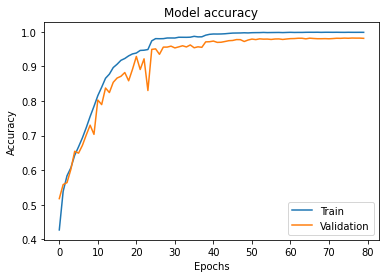

In [ ]:
plt.plot(modelhist['accuracy'])
plt.plot(modelhist['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['Train','Validation'],loc='center right')
plt.savefig("/content/drive/MyDrive/Thesis29_10_22/acc.png",dpi=400)
plt.show()

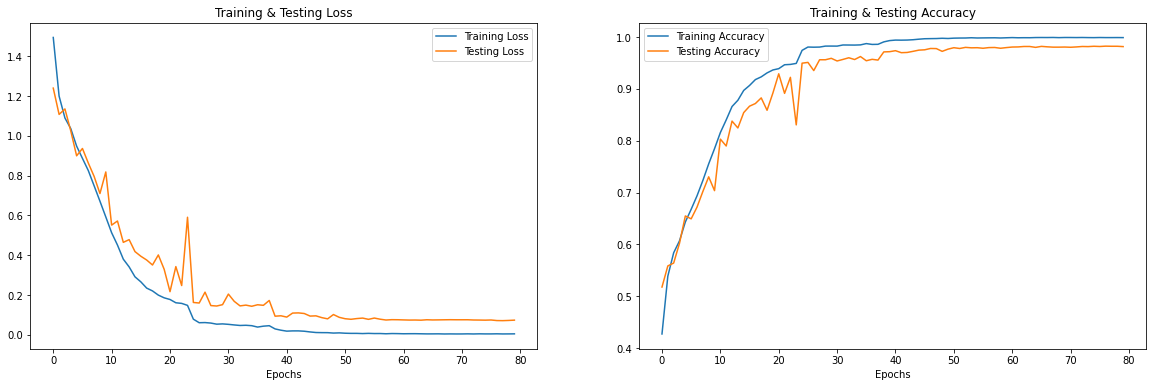

In [ ]:
epochs = [i for i in range(80) ]
fig , ax = plt.subplots(1,2)
train_acc = modelhist['accuracy']
train_loss = modelhist['loss']
test_acc = modelhist['val_accuracy']
test_loss = modelhist['val_loss']

fig.set_size_inches(20,6)
ax[0].plot(epochs , train_loss , label = 'Training Loss')
ax[0].plot(epochs , test_loss , label = 'Testing Loss')
ax[0].set_title('Training & Testing Loss')
ax[0].legend()
ax[0].set_xlabel("Epochs")

ax[1].plot(epochs , train_acc , label = 'Training Accuracy')
ax[1].plot(epochs , test_acc , label = 'Testing Accuracy')
ax[1].set_title('Training & Testing Accuracy')
ax[1].legend()
ax[1].set_xlabel("Epochs")
plt.savefig("/content/drive/MyDrive/Thesis29_10_22/lossaccuracy_curve.png",dpi=400)

plt.show()

In [ ]:
pred_test = model.predict(x_test)

y_pred = encoder.inverse_transform(pred_test)

y_test = encoder.inverse_transform(y_test)

147/147 [==============================] - 141s 947ms/step


In [ ]:
pred_test=model.predict(x_test)

147/147 [==============================] - 136s 928ms/step


In [ ]:
df = pd.DataFrame(columns=['Predicted Labels', 'Actual Labels'])
df['Predicted Labels'] = y_pred.flatten()
df['Actual Labels'] = y_test.flatten()

df.head(20)

,Predicted Labels,Actual Labels
0,fear,fear
1,fear,fear
2,surprise,surprise
3,happy,happy
4,happy,happy
5,fear,fear
6,disgust,disgust
7,happy,happy
8,fear,fear
9,fear,fear


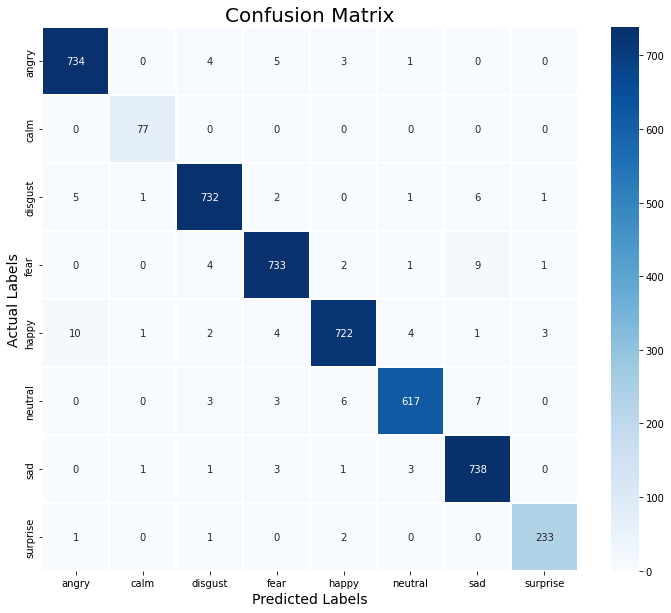

In [ ]:
#Confusion_matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize = (12, 10))
cm = pd.DataFrame(cm , index = [i for i in encoder.categories_] , columns = [i for i in encoder.categories_])
sns.heatmap(cm, linecolor='white', cmap='Blues', linewidth=1, annot=True, fmt='')
plt.title('Confusion Matrix', size=20)
plt.xlabel('Predicted Labels', size=14)
plt.ylabel('Actual Labels', size=14)
plt.savefig("/content/drive/MyDrive/Thesis29_10_22/confusion_matrix",dpi=400)

plt.show()

In [ ]:
%%time
Y_pred = model.predict(x_test)

147/147 [==============================] - 133s 907ms/step
CPU times: user 4min 7s, sys: 4.07 s, total: 4min 11s
Wall time: 2min 22s


In [ ]:
Y_pred = model.predict(x_test)

147/147 [==============================] - 134s 913ms/step


In [ ]:
Y_predBin = np.where(Y_pred > 0.5, 1, 0)

In [ ]:
y_val[0:10,:]

array([[1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0.]])

In [ ]:
Y_predBin[0:10,:]

array([[0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0]])

In [ ]:
Y_pred[0:5,:]

array([[1.8718501e-06, 5.9057331e-10, 1.2350943e-06, 9.9999636e-01,
        4.6423494e-07, 4.8175778e-08, 3.6753665e-08, 1.4603573e-08],
       [3.6735606e-10, 1.6453451e-10, 3.0489857e-11, 9.9999994e-01,
        5.4839088e-08, 3.5251437e-09, 2.1291588e-09, 5.8386837e-11],
       [1.6253500e-11, 2.4950644e-10, 3.9722861e-13, 3.2196397e-07,
        2.4612593e-10, 1.8330070e-09, 1.7069721e-11, 9.9999958e-01],
       [1.8655841e-09, 1.2210803e-10, 5.1436183e-10, 1.0864177e-07,
        9.9999982e-01, 3.7960337e-09, 3.6269463e-11, 1.8150313e-09],
       [1.2085051e-05, 1.3490795e-15, 5.7641175e-13, 2.8004055e-10,
        9.9998790e-01, 5.6899407e-12, 1.0820905e-15, 2.0004447e-09]],
      dtype=float32)

In [ ]:
x_test[1,:].shape

(2376, 1)

In [ ]:
%%time
#Y_pred1 = model.predict(x_test[1,:])

CPU times: user 4 µs, sys: 0 ns, total: 4 µs
Wall time: 9.3 µs


In [ ]:
from sklearn.metrics import roc_curve, auc

In [ ]:
cls = encoder.categories_

In [ ]:
cls[0][1]

'calm'

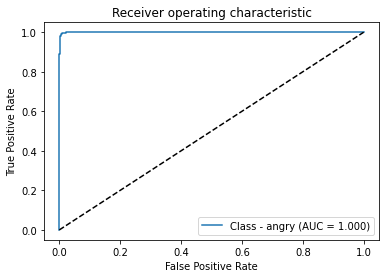

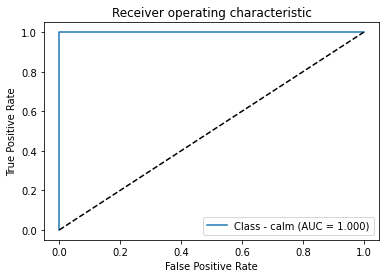

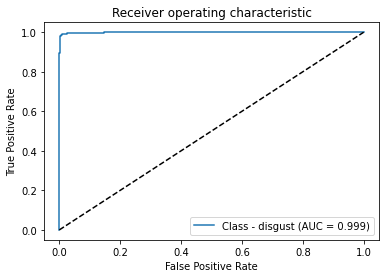

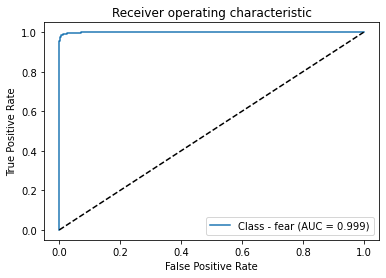

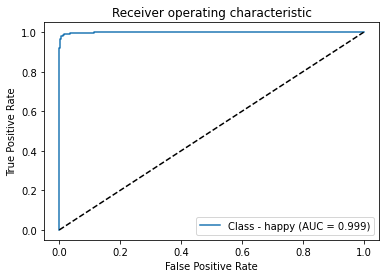

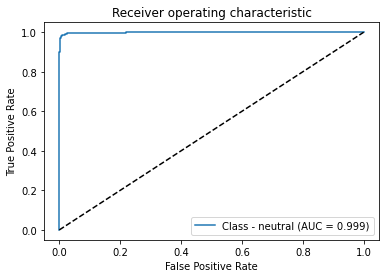

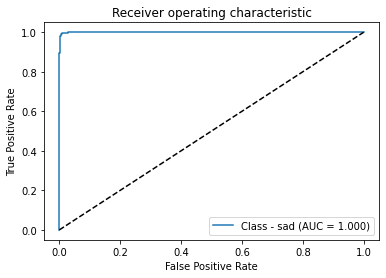

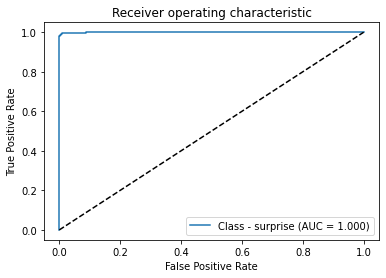

In [ ]:
# Compute ROC curve and ROC area for each class
n_classes=8
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], Y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot of a ROC curve for a specific class
for i in range(n_classes):
    plt.figure()
    plt.plot(fpr[i], tpr[i], label='Class - %s (AUC = %0.3f)' %(cls[0][i], roc_auc[i]))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver operating characteristic')
    plt.legend(loc="lower right")
    plt.savefig("/content/drive/MyDrive/Thesis29_10_22/cls",dpi=400)

    plt.show()

In [ ]:
from cycler import cycler
custom_col = (cycler(color=['r','b','m','g']))

In [ ]:
custom_col

'r'
'b'
'm'
'g'


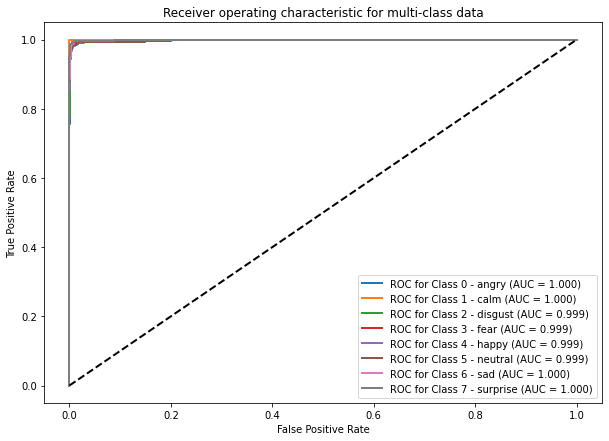

In [ ]:
#For all ROC in single plot
fpr = dict()
tpr = dict()
roc_auc = dict()
lw=2
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], Y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
#colors = cycler(['blue', 'red', 'green'])
#for i, color in zip(range(n_classes), colors):
plt.figure(figsize=(10,7))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], lw=2, label='ROC for Class %d - %s (AUC = %0.3f)' %(i, cls[0][i], roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic for multi-class data')
plt.legend(loc="lower right")
plt.savefig
plt.show()

In [ ]:

sys.path.append('/content/drive/MyDrive/Thesis29_10_22')



In [ ]:
modelhistory = np.load('history.npy', allow_pickle = True).item()

SyntaxError: ignored

In [ ]:
modelhistory = np.load('/content/drive/MyDrive/Thesis29_10_22/historynewfeatures.npy')

In [ ]:
#code for high resolution picture saving
plt.plot(modelhistory['acc'])
plt.plot(modelhistory['val_acc'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['Train', 'Validation'], loc='center right')
plt.savefig("/content/drive/MyDrive/..../accuracy.png",  dpi=400)
plt.show()